# Backtest: โมเดลคะแนนการเติบโต (`growth_score.py`) ตั้งแต่เตรียมข้อมูลจนถึงประเมินผล

**โมเดลนี้ทำอะไร:** เรียงลำดับคีย์เวิร์ด (และเทรนด์) ว่า "ตัวไหนจะมีคนค้นหาโตมากกว่ากัน" ในอีก **1 ถึง 5 ปีข้างหน้า** (🆕 2026-10-02 เดิม 1-3 ปี: ระยะสั้น = ปีที่ 1-2, ระยะยาว = ปีที่ 3-5)
ผลที่ได้คือคะแนน 0-1 ใช้จัดอันดับเทรนด์ในขั้น ⑥ (`rank_trends.py` เรียก `growth_score.compute_growth_scores`) แทน Z_Delta ตั้งแต่ 30 ก.ย. 2026

**คำถามของ backtest:** ถ้าย้อนเวลากลับไปในอดีต ฝึกโมเดลด้วยข้อมูลที่ "รู้ ณ วันนั้น" แล้วให้เรียงลำดับคีย์เวิร์ด
ลำดับที่ได้ตรงกับสิ่งที่เกิดขึ้นจริงอีก 1-5 ปีต่อมาแค่ไหน

```
step5a (ค่า Google Trends รายเดือน)
   │
   ├─ 1 Prepare Data         โหลด → เช็กช่วงที่ข้อมูลผิดปกติ → กรองข้อมูลบาง → นิยาม "การเติบโต" (เป้าหมาย)
   ├─ 2 Feature Engineering  15 ฟีเจอร์ต่อ (คีย์เวิร์ด, เดือน) ที่ใช้แค่ข้อมูลถึงเดือนนั้น
   ├─ 3 Modeling             RandomForest 1 ตัวต่อปี เรียนจากทุกคีย์เวิร์ดร่วมกัน → คะแนน percentile
   ├─ 4 Backtest             walk-forward 13 จุดตัด (ปีที่ 4 = 11, ปีที่ 5 = 9): ฝึกเฉพาะผลที่รู้แล้ว ณ วันนั้น → ทายทั้งชุด
   └─ 5 Evaluation           ลำดับที่ทายตรงกับลำดับจริงแค่ไหน (Spearman) เทียบ momentum / mean reversion / blend
```

| ขั้น | ทำอะไร |
|---|---|
| **0. Setup** | import + ค่าตั้งต้นทั้งหมดไว้ที่เดียว |
| **1. Prepare Data** | โหลด step5a → ดูการกระโดดของข้อมูล cat=0 → กรองข้อมูลบาง → นิยามเป้าหมาย |
| **2. Feature Engineering** | สร้างฟีเจอร์ + เช็กว่า "ไม่เห็นอนาคต" → ตารางตัวอย่างฝึกทั้งหมด |
| **3. Modeling** | เลือกตัวอย่างฝึกตามเวลา → เทรน → ทายเดือนล่าสุด → เช็กว่าตรงกับโค้ดจริงและผลที่ใช้ในรายงาน |
| **4. Backtest** | walk-forward ทุก 6 เดือน 2016-06 ถึง 2022-06 |
| **5. Evaluation** | ระดับคีย์เวิร์ด, ระดับเทรนด์ (หน่วยที่ขึ้นรายงาน) + ช่วงคลาดเคลื่อน 80%, เหตุผลที่ตอนนี้ใช้โมเดลอย่างเดียว, สรุปผล |

ทุกขั้นเขียนซ้ำจาก `tool/phase2_three_streams/growth_score.py` ให้อ่านทีละขั้นได้ แล้วขั้น 3.4 เช็กว่าได้ค่าตรงกับโค้ดจริงทุกหลัก ·
**ไม่เรียก API/LLM ใดๆ** · เปิดจากโฟลเดอร์ `main/` · รันทั้งไฟล์ใช้เวลาราว 4-5 นาที

> **ไม่ครอบคลุม:** ตัวพยากรณ์ ⑦ (RandomForest บน z-score) ที่ใช้วาดเส้นพยากรณ์รุ่นก่อน ไม่ได้ใช้จัดอันดับแล้ว
> (backtest 30 ก.ย. พบว่าความแม่นทิศทางของมันมาจาก mean reversion เกือบทั้งหมด) notebook รุ่นนั้นเก็บไว้ที่
> `output/_backups/backtest_ipynb_before_trim_20260930/backtest.ipynb`

## 0. Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---------- สไตล์กราฟ (น้ำเงิน = โมเดล, ส้ม = momentum, เขียวน้ำทะเล = blend, เทา = baseline อ้างอิง; ปี 1/2/3 = ไล่เฉดน้ำเงิน) ----------
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
YEAR_COLORS = {1: "#b5d3f6", 2: "#86b6ef", 3: "#2a78d6", 4: "#1a5aaa", 5: "#0c3470"}
plt.rcParams.update({
    "font.family": ["Leelawadee UI", "Segoe UI", "Tahoma", "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titlelocation": "left", "lines.linewidth": 1.8,
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 100,
})

# ---------- ค่าของโมเดล (ต้องตรงกับ growth_score.py - ขั้น 3.4 เช็กให้) ----------
SAMPLE_START = pd.Timestamp("2008-01-01")          # ตัวอย่างฝึกเริ่มตั้งแต่เดือนนี้
LAST_TRUSTED_MONTH = pd.Timestamp("2025-06-01")    # ข้อมูลหลังเดือนนี้กระโดดผิดปกติ (ดูขั้น 1.2) ไม่ใช้เป็นผลจริงของการฝึก
HORIZONS = {1: (1, 12), 2: (13, 24), 3: (25, 36), 4: (37, 48), 5: (49, 60)}  # ปีที่ h = เดือนที่ a ถึง b หลังเดือนที่ทาย
BASE_FEATURES = ["growth_past_12m", "growth_past_6m", "growth_past_3m", "slope_24m", "level_vs_peak",
                 "volatility_12m", "pct_nonzero_24m", "z_now", "months_since_first_search",
                 "yoy_3m", "yoy_6m", "accel_12m"]                                  # 🆕 2026-10-02 + 3 ตัวท้าย
LONG_FEATURES = BASE_FEATURES + ["growth_past_36m", "years_up_of_5", "slope_60m"]
MODEL_FEATURES = {1: BASE_FEATURES, **{h: LONG_FEATURES for h in (2, 3, 4, 5)}}
RF_PARAMS = {"n_estimators": 300, "min_samples_leaf": 20, "random_state": 42, "n_jobs": -1}
BLEND_MOMENTUM = False                             # False = คะแนนจากโมเดลอย่างเดียว (ตั้งแต่ 1 ต.ค. 2026 ดูขั้น 5.5)
PIT_SCALING = False                                # True = ปรับสเกลตัวอย่างฝึก ณ เดือนนั้น (ขั้น 2.3) - ยังปิด ดูขั้น 5.6

# ---------- ค่าเฉพาะ backtest ----------
RUN_ID = "beauty_and_personal_care_20260916_082438"           # รอบรันที่ใช้ข้อมูล
EVAL_CUTOFFS = pd.date_range("2016-06-01", "2022-06-01", freq="6MS")   # จุดตัด: วันที่ "ทาย" (ทุก 6 เดือน, 13 จุด)
GROWTH_THRESHOLD = np.log(1.10)                    # โตเกิน 10% = "โตจริง"
EXAMPLE_KEYWORD = "pregnancy safe skincare"        # คีย์เวิร์ดตัวอย่างสำหรับดูทีละขั้น
EXAMPLE_CUTOFF = pd.Timestamp("2019-06-01")

MAIN = Path.cwd()
if not (MAIN / "tool").exists():       # เปิดจาก notebooks/ -> ขึ้นไปโฟลเดอร์บนสุดของ repo
    MAIN = MAIN.parent
assert (MAIN / "tool").exists(), "ให้เปิดโน้ตบุ๊กจากโฟลเดอร์บนสุดของ repo หรือจาก notebooks/"
FORECAST_DIR = MAIN / "output" / RUN_ID / "serpapi_forecast_run"
# ผลจริงปีที่ h ต้องจบไม่เกินช่วงที่ข้อมูลเชื่อได้ ไม่งั้น "ผลจริง" จะปนช่วงที่กระโดด - ปีที่ 1-3 ใช้ครบ 13 จุดตัด
# ปีที่ 4-5 ต้องรอเฉลยนานกว่า จึงเหลือ 11 / 9 จุดตัด (จุดตัดสุดท้าย + 48 / 60 เดือน <= 2025-06)
def cutoffs_for(h):
    return [c for c in EVAL_CUTOFFS if c + pd.DateOffset(months=HORIZONS[h][1]) <= LAST_TRUSTED_MONTH]


assert len(cutoffs_for(3)) == len(EVAL_CUTOFFS)
print(f"{len(EVAL_CUTOFFS)} จุดตัด: {EVAL_CUTOFFS[0]:%Y-%m} ถึง {EVAL_CUTOFFS[-1]:%Y-%m} · จำนวนจุดตัดที่ใช้ต่อปี "
      f"{ {h: len(cutoffs_for(h)) for h in HORIZONS} }")

13 จุดตัด: 2016-06 ถึง 2022-06 · จำนวนจุดตัดที่ใช้ต่อปี {1: 13, 2: 13, 3: 13, 4: 11, 5: 9}


## 1. Prepare Data

### 1.1 โหลดข้อมูล
`step5a_monthly_trends.xlsx` = ความสนใจการค้นหา Google Trends ทั่วโลก **รายเดือน** ของทุกคีย์เวิร์ดในรอบรัน (ดึงจาก SerpAPI ในขั้น ⑦)
ค่า `search_avg` อยู่ในสเกล 0-100 ของ Google Trends · `step5b` บอกว่าแต่ละคีย์เวิร์ดอยู่เทรนด์ (cluster) ไหน

โค้ดของโมเดลอ้าง **ตำแหน่งแถว** (`values[i-11:i+1]` = 12 เดือนล่าสุด) จึงต้องเช็กว่าทุกคีย์เวิร์ดมีเดือนต่อเนื่อง ไม่มีเดือนหาย

In [2]:
monthly = pd.read_excel(FORECAST_DIR / "step5a_monthly_trends.xlsx")
monthly["Keyword"] = monthly["Keyword"].astype(str).str.strip().str.lower()
monthly["start_date"] = pd.to_datetime(monthly["start_date"])

# เก็บเป็น {คีย์เวิร์ด: อนุกรมรายเดือน} ใช้ง่ายกว่าตารางยาว
series_by_keyword = {
    keyword: group.set_index("start_date")["search_avg"].astype(float).sort_index()
    for keyword, group in monthly.groupby("Keyword")
}
mapping = pd.read_excel(FORECAST_DIR / "step5b_df_keyword_processed.xlsx",
                        usecols=["Keyword", "cluster_name"]).drop_duplicates()
mapping["Keyword"] = mapping["Keyword"].astype(str).str.strip().str.lower()

for keyword, s in series_by_keyword.items():          # เช็กว่าเดือนต่อเนื่อง ไม่มีเดือนหาย
    assert (s.index == pd.date_range(s.index.min(), s.index.max(), freq="MS")).all(), keyword

print(f"{len(series_by_keyword)} คีย์เวิร์ด · {mapping['cluster_name'].nunique()} เทรนด์ · "
      f"{monthly['start_date'].min():%Y-%m} ถึง {monthly['start_date'].max():%Y-%m} ({len(next(iter(series_by_keyword.values())))} เดือน)")
monthly.head()

145 คีย์เวิร์ด · 15 เทรนด์ · 2004-01 ถึง 2026-08 (272 เดือน)


,Keyword,start_date,search_avg
0,acne scars,2004-01-01,22
1,acne scars,2004-02-01,21
2,acne scars,2004-03-01,19
3,acne scars,2004-04-01,20
4,acne scars,2004-05-01,23


### 1.2 เช็กช่วงที่ข้อมูลผิดปกติ (ที่มาของ `LAST_TRUSTED_MONTH`)
ข้อมูล Google Trends แบบไม่ระบุหมวด (cat=0) **กระโดดขึ้นพร้อมกันทุกคีย์เวิร์ดตั้งแต่ ส.ค. 2025** — ฝั่ง Google ไม่ใช่ความสนใจจริงที่เพิ่มขึ้น
(ทดสอบเทียบกับ cat=143 เมื่อ 30 ก.ย. 2026) ถ้าเอาช่วงนี้ไปเป็น "ผลจริง" ของการฝึก โมเดลจะเรียนการกระโดดนั้นเป็นรูปแบบการเติบโตของจริง
จึงตั้ง `LAST_TRUSTED_MONTH = 2025-06`: **ตัวอย่างฝึกที่ผลจริงเลยเดือนนี้ไปไม่ถูกใช้** (ดูขั้น 3.1)

กราฟด้านล่าง: ทุกคำเทียบกับระดับของตัวเองในช่วง 2023-01 ถึง 2024-06 แล้วหามัธยฐานของทั้งตลาด (1.0 = ระดับปกติ)

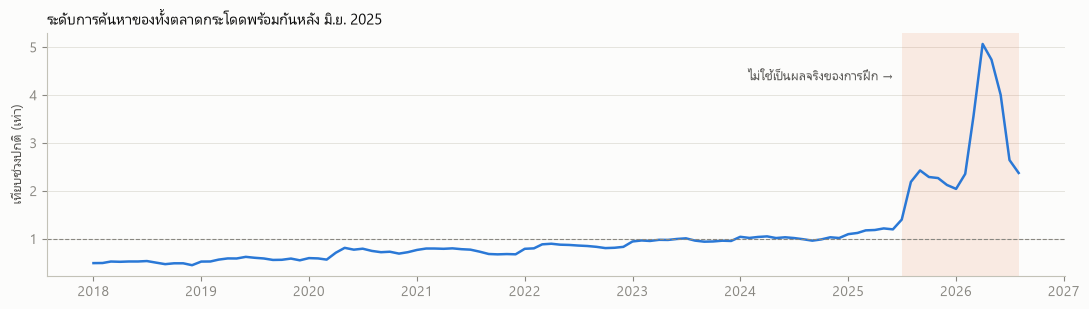

มัธยฐานทั้งตลาด: 2024-12 = 1.02 · 2025-06 = 1.20 · 2025-08 = 2.19 · 2026-04 = 5.07


In [3]:
levels = pd.DataFrame(series_by_keyword)                       # แถว = เดือน, คอลัมน์ = คีย์เวิร์ด
normal_level = levels.loc["2023-01":"2024-06"].mean()
relative = levels.div(normal_level.where(normal_level > 0))     # คำที่ช่วงปกติเป็น 0 ทั้งหมดข้ามไป
market_level = relative.median(axis=1)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(market_level["2018":].index, market_level["2018":].values, color=BLUE)
ax.axhline(1.0, color=GREY, lw=0.8, ls="--")
ax.axvspan(LAST_TRUSTED_MONTH + pd.DateOffset(months=1), market_level.index.max(), color=ORANGE, alpha=0.12, lw=0)
ax.text(LAST_TRUSTED_MONTH, market_level["2018":].max() * 0.9, "ไม่ใช้เป็นผลจริงของการฝึก →",
        color=INK_2, fontsize=9, va="top", ha="right")
ax.set_ylabel("เทียบช่วงปกติ (เท่า)")
ax.set_title("ระดับการค้นหาของทั้งตลาดกระโดดพร้อมกันหลัง มิ.ย. 2025")
plt.tight_layout()
plt.show()
at = lambda ym: market_level.loc[pd.Timestamp(ym + "-01")]
print(f"มัธยฐานทั้งตลาด: 2024-12 = {at('2024-12'):.2f} · 2025-06 = {at('2025-06'):.2f} · "
      f"2025-08 = {at('2025-08'):.2f} · 2026-04 = {at('2026-04'):.2f}")

### 1.3 กรองข้อมูลบาง
คีย์เวิร์ดหางยาวหลายตัวมีคนค้นน้อยจน Google Trends ให้ค่า 0 เกือบทั้งเส้น — คิด "อัตราการโต" ไม่ได้ (0 → 1 กลายเป็นโต 100%)
เกณฑ์ของโมเดล: ณ เดือน `i` ต้องมีข้อมูลย้อนหลังอย่างน้อย 24 เดือน (ฟีเจอร์ต้องใช้) และใน 12 เดือนล่าสุด
**มีค่ามากกว่า 0 อย่างน้อย 6 เดือน และค่าเฉลี่ยไม่ต่ำกว่า 1** — ไม่ผ่าน = "thin" ไม่ถูกนำมาฝึก ไม่ถูกจัดอันดับ

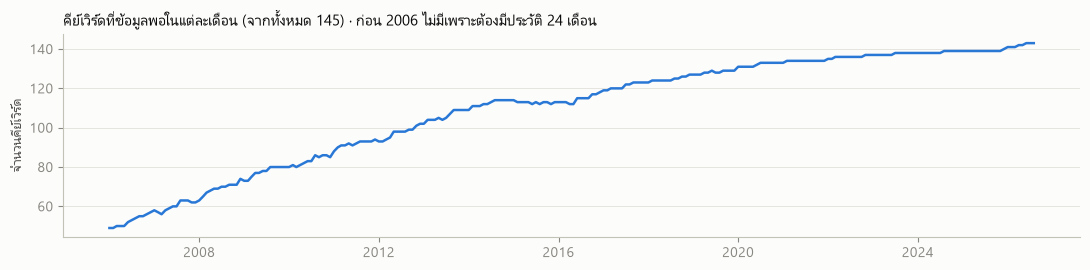

เดือนล่าสุด (2026-08): ข้อมูลพอ 143 · thin 2 → ['fast absorbing spf', 'lung safe makeup']
จุดตัด backtest แรก (2016-06): ข้อมูลพอ 115 คีย์เวิร์ด


In [4]:
def has_enough_data(values, i):
    if i < 23:
        return False
    past = values[i - 11:i + 1]                      # 12 เดือนล่าสุด
    return (past > 0).sum() >= 6 and past.mean() >= 1


usable = pd.DataFrame({k: [has_enough_data(s.to_numpy(dtype=float), i) for i in range(len(s))]
                       for k, s in series_by_keyword.items()}, index=levels.index)

fig, ax = plt.subplots(figsize=(11, 2.8))
enough_by_month = usable.sum(axis=1)["2006":]                 # ก่อน 2006 ยังไม่มีคำไหนมีประวัติครบ 24 เดือน
ax.plot(enough_by_month.index, enough_by_month.values, color=BLUE)
ax.set_ylabel("จำนวนคีย์เวิร์ด")
ax.set_title(f"คีย์เวิร์ดที่ข้อมูลพอในแต่ละเดือน (จากทั้งหมด {usable.shape[1]}) · ก่อน 2006 ไม่มีเพราะต้องมีประวัติ 24 เดือน")
plt.tight_layout()
plt.show()

thin_now = usable.columns[~usable.iloc[-1]].tolist()
print(f"เดือนล่าสุด ({usable.index[-1]:%Y-%m}): ข้อมูลพอ {int(usable.iloc[-1].sum())} · thin {len(thin_now)} → {thin_now}")
print(f"จุดตัด backtest แรก ({EVAL_CUTOFFS[0]:%Y-%m}): ข้อมูลพอ {int(usable.loc[EVAL_CUTOFFS[0]].sum())} คีย์เวิร์ด")

### 1.4 นิยามเป้าหมาย (target) = "การเติบโต"
ณ เดือน `i` (เดือนที่ทาย) กำหนด

**การเติบโตปีที่ h = log( ค่าเฉลี่ยการค้นหาในปีที่ h ข้างหน้า ÷ ค่าเฉลี่ย 12 เดือนที่ผ่านมา )**

- ปีที่ 1 = เดือนที่ +1 ถึง +12 · ปีที่ 2 = +13 ถึง +24 · ปีที่ 3 = +25 ถึง +36 · ปีที่ 4 = +37 ถึง +48 · ปีที่ 5 = +49 ถึง +60
- ใช้ **ค่าเฉลี่ยทั้งปี** ไม่ใช่ค่ารายเดือน เพราะรายเดือนแกว่งตามฤดูกาลและสัญญาณรบกวน (กันแดดขึ้นหน้าร้อนทุกปี ไม่ใช่เทรนด์โต)
- ใช้ **log ของอัตราส่วน** (บวก 1 ทั้งเศษและส่วนกันหารด้วย 0): +0.10 ≈ โต 10%, −0.10 ≈ หด 10% และบวกลบสมมาตรกัน
- ตัวอย่างที่ข้อมูลยังไปไม่ถึงปีนั้น (เช่น เดือนล่าสุดของข้อมูล) = ยังไม่มีเป้าหมาย (NaN) → ใช้ฝึกไม่ได้ แต่ใช้ "ทาย" ได้

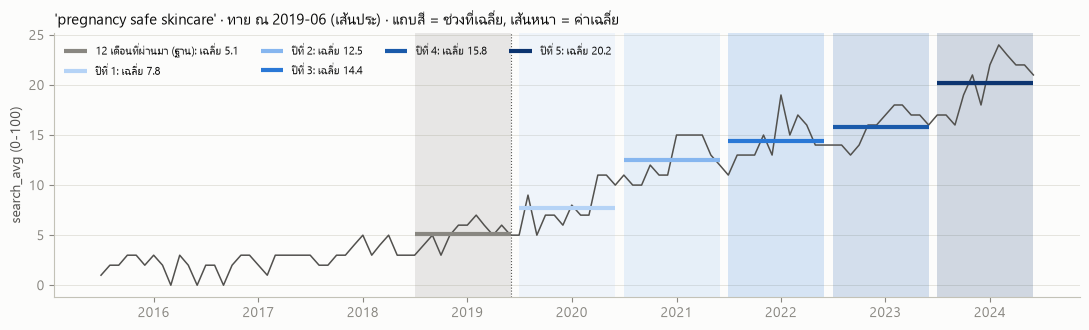

,ค่าเฉลี่ยของช่วง,เป้าหมาย (log),≈ โตกี่ %
ปีที่ 1,7.750,0.364,43.836
ปีที่ 2,12.500,0.797,121.918
ปีที่ 3,14.417,0.930,153.425
ปีที่ 4,15.833,1.018,176.712
ปีที่ 5,20.167,1.247,247.945


In [5]:
def log_growth(new_mean, old_mean):
    return float(np.log((new_mean + 1) / (old_mean + 1)))


def targets_at(values, i):
    past_mean = values[i - 11:i + 1].mean()
    return {f"t_y{h}": (log_growth(values[i + a:i + b + 1].mean(), past_mean) if i + b < len(values) else np.nan)
            for h, (a, b) in HORIZONS.items()}


example = series_by_keyword[EXAMPLE_KEYWORD]
i_ex = example.index.get_loc(EXAMPLE_CUTOFF)
v_ex = example.to_numpy(dtype=float)

windows = {"12 เดือนที่ผ่านมา (ฐาน)": (i_ex - 11, i_ex, GREY)}
windows.update({f"ปีที่ {h}": (i_ex + a, i_ex + b, YEAR_COLORS[h]) for h, (a, b) in HORIZONS.items()})

fig, ax = plt.subplots(figsize=(11, 3.4))
span = slice(i_ex - 47, i_ex + 61)
ax.plot(example.index[span], v_ex[span], color=INK_2, lw=1.1)
for label, (a, b, color) in windows.items():
    mean = v_ex[a:b + 1].mean()
    ax.axvspan(example.index[a], example.index[b], color=color, alpha=0.18, lw=0)
    ax.hlines(mean, example.index[a], example.index[b], color=color, lw=3, label=f"{label}: เฉลี่ย {mean:.1f}")
ax.axvline(EXAMPLE_CUTOFF, color=INK_2, lw=0.8, ls=":")
ax.set_ylabel("search_avg (0-100)")
ax.set_title(f"'{EXAMPLE_KEYWORD}' · ทาย ณ {EXAMPLE_CUTOFF:%Y-%m} (เส้นประ) · แถบสี = ช่วงที่เฉลี่ย, เส้นหนา = ค่าเฉลี่ย")
ax.legend(ncol=4, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

targets = targets_at(v_ex, i_ex)
pd.DataFrame({"ค่าเฉลี่ยของช่วง": [v_ex[windows[k][0]:windows[k][1] + 1].mean() for k in windows][1:],
              "เป้าหมาย (log)": list(targets.values()),
              "≈ โตกี่ %": [100 * np.expm1(t) for t in targets.values()]},
             index=[f"ปีที่ {h}" for h in HORIZONS]).round(3)

## 2. Feature Engineering

**1 ตัวอย่าง = 1 คีย์เวิร์ด ณ 1 เดือน** · ฟีเจอร์ทุกตัวคำนวณจาก `values[:i+1]` เท่านั้น (ข้อมูลถึงเดือน `i` ไม่เห็นอนาคต)
แนวคิด: ให้โมเดลดูว่า "ตอนนั้น" คีย์เวิร์ดอยู่ในสภาพไหน — โตมาแค่ไหน เร่งหรือชะลอ ใกล้จุดสูงสุดไหม แกว่งแค่ไหน เก่าแค่ไหน

| ฟีเจอร์ | ความหมาย | ใช้ในปี |
|---|---|---|
| `growth_past_12m` | 12 เดือนล่าสุดโตจากปีก่อนหน้าแค่ไหน (**momentum**) | 1-5 |
| `growth_past_6m` | 6 เดือนล่าสุดเทียบ 6 เดือนก่อนหน้า | 1-5 |
| `growth_past_3m` | 3 เดือนล่าสุดเทียบ 3 เดือนก่อนหน้า | 1-5 |
| `slope_24m` | ความชันของ log(ค่า) ใน 24 เดือนล่าสุด (โตต่อเดือน) | 1-5 |
| `level_vs_peak` | ค่าเฉลี่ย 12 เดือนล่าสุด ÷ ค่าสูงสุดที่เคยมี (ใกล้ 1 = อยู่ใกล้จุดสูงสุด) | 1-5 |
| `volatility_12m` | ความผันผวนรายเดือนของ log(ค่า) ใน 12 เดือนล่าสุด | 1-5 |
| `pct_nonzero_24m` | สัดส่วนเดือนที่มีข้อมูลใน 24 เดือนล่าสุด | 1-5 |
| `z_now` | z-score เดือนนี้เทียบ 12 เดือนล่าสุด (ตัวเดียวกับที่ ⑦ ใช้) ใส่ไว้ให้โมเดลเลือกใช้เอง | 1-5 |
| `months_since_first_search` | เริ่มมีคนค้นมาแล้วกี่เดือน (ความเก่าของเทรนด์) | 1-5 |
| `yoy_3m` 🆕 | 3 เดือนล่าสุดเทียบ 3 เดือนเดียวกันของปีก่อน (ตัดฤดูกาลออก ต่างจาก `growth_past_3m`) | 1-5 |
| `yoy_6m` 🆕 | 6 เดือนล่าสุดเทียบ 6 เดือนเดียวกันของปีก่อน | 1-5 |
| `accel_12m` 🆕 | การโตปีล่าสุด ลบ การโตปีก่อนหน้า (เร่งหรือชะลอ) | 1-5 |
| `growth_past_36m` | 12 เดือนล่าสุดเทียบ 3 ปีก่อน (ประวัติยาว) | 2-5 |
| `years_up_of_5` | ใน 5 ปีที่ผ่านมา กี่ปีที่ค่าเฉลี่ยสูงกว่าปีก่อนหน้า (ความสม่ำเสมอ) | 2-5 |
| `slope_60m` | ความชันของ log(ค่า) ใน 60 เดือนล่าสุด | 2-5 |

ปีที่ 2-5 ได้ฟีเจอร์ประวัติยาว 3 ตัวเพิ่ม (ใน backtest ปีที่ 3 ดีขึ้นใน 8 จาก 13 จุดตัด) — ถ้าข้อมูลย้อนหลังไม่พอ ค่าเป็น NaN
· 🆕 3 ตัว (2026-10-02) ทดสอบกับข้อมูล 2 รอบ (082438 + 111455) ดีขึ้น +0.02..+0.05 ทุกปี ·
**ห้ามเพิ่มฟีเจอร์ "ระดับ" ดิบ** (เช่น log ของค่าเฉลี่ย): Google Trends ปรับสเกลแต่ละคำให้ค่าสูงสุดทั้งช่วง (รวมอนาคต) = 100
ระดับในอดีตจึงแอบรู้ว่าอนาคตจะขึ้นไปถึงไหน (ทดลองแล้วได้ +0.15 ปลอมๆ ที่ปีที่ 5)
(RandomForest ของ sklearn รับ NaN ได้)

### 2.1 ฟังก์ชันสร้างฟีเจอร์

In [6]:
def features_at(values, i):
    past = values[i - 11:i + 1]                                  # 12 เดือนล่าสุด
    log_values = np.log(values[:i + 1] + 1)                      # log ของประวัติทั้งหมดถึงเดือน i
    std = past.std(ddof=1)
    # ค่าเฉลี่ย 12 เดือนของแต่ละปีย้อนหลัง (k=0 คือ 12 เดือนล่าสุด) - NaN ถ้าข้อมูลไม่พอ
    yearly = [values[i - 12 * k - 11:i - 12 * k + 1].mean() if i - 12 * k - 11 >= 0 else np.nan for k in range(6)]
    return {
        "growth_past_12m": log_growth(past.mean(), values[i - 23:i - 11].mean()),
        "growth_past_6m": log_growth(values[i - 5:i + 1].mean(), values[i - 11:i - 5].mean()),
        "growth_past_3m": log_growth(values[i - 2:i + 1].mean(), values[i - 5:i - 2].mean()),
        "slope_24m": float(np.polyfit(np.arange(24), log_values[-24:], 1)[0]),
        "level_vs_peak": float(past.mean() / max(values[:i + 1].max(), 1)),
        "volatility_12m": float(np.std(np.diff(log_values[-13:]))),
        "pct_nonzero_24m": float((values[i - 23:i + 1] > 0).mean()),
        "z_now": float((values[i] - past.mean()) / std) if std > 0 else 0.0,
        "months_since_first_search": int(i - np.argmax(values[:i + 1] > 0)),
        "growth_past_36m": log_growth(past.mean(), yearly[3]) if not np.isnan(yearly[3]) else np.nan,
        "years_up_of_5": (float(sum(yearly[k] > yearly[k + 1] for k in range(5)))
                          if not np.isnan(yearly[5]) else np.nan),
        "slope_60m": float(np.polyfit(np.arange(60), log_values[-60:], 1)[0]) if i >= 59 else np.nan,
        "yoy_3m": log_growth(values[i - 2:i + 1].mean(), values[i - 14:i - 11].mean()),
        "yoy_6m": log_growth(values[i - 5:i + 1].mean(), values[i - 17:i - 11].mean()),
        "accel_12m": (log_growth(past.mean(), values[i - 23:i - 11].mean())
                      - log_growth(values[i - 23:i - 11].mean(), values[i - 35:i - 23].mean())) if i >= 35 else np.nan,
    }


features_example = features_at(v_ex, i_ex)
pd.DataFrame({"ค่า": features_example, "ใช้ในปี": {f: "".join(str(h) for h in HORIZONS if f in MODEL_FEATURES[h])
                                                    for f in features_example}}).round(3)

,ค่า,ใช้ในปี
growth_past_12m,0.339,12345
growth_past_6m,0.248,12345
growth_past_3m,-0.147,12345
slope_24m,0.030,12345
level_vs_peak,0.726,12345
volatility_12m,0.210,12345
pct_nonzero_24m,1.000,12345
z_now,-0.067,12345
months_since_first_search,117.000,12345
growth_past_36m,0.735,2345


### 2.2 เช็กว่า "ไม่เห็นอนาคต" (data leakage test)
สลับค่าทุกเดือนหลังเดือนที่ทายด้วยเลขสุ่ม → ฟีเจอร์ต้องไม่เปลี่ยนแม้แต่หลักเดียว (ส่วนเป้าหมายต้องเปลี่ยน เพราะมันคือ "อนาคต")

In [7]:
tampered = v_ex.copy()
tampered[i_ex + 1:] = np.random.default_rng(0).uniform(0, 100, len(tampered) - i_ex - 1)

pd.testing.assert_series_equal(pd.Series(features_at(v_ex, i_ex)), pd.Series(features_at(tampered, i_ex)))
print("✅ ฟีเจอร์เหมือนเดิมทุกตัว แม้อนาคตถูกสลับเป็นเลขสุ่ม")
print("   เป้าหมายปีที่ 1 เดิม", round(targets_at(v_ex, i_ex)["t_y1"], 3), "→ หลังสลับ", round(targets_at(tampered, i_ex)["t_y1"], 3))

✅ ฟีเจอร์เหมือนเดิมทุกตัว แม้อนาคตถูกสลับเป็นเลขสุ่ม
   เป้าหมายปีที่ 1 เดิม 0.364 → หลังสลับ 2.178


### 2.3 สร้างตารางตัวอย่างฝึกทั้งหมด
ทุกคีย์เวิร์ด × ทุกเดือนตั้งแต่ ม.ค. 2008 ที่ข้อมูลพอ → 1 แถว = ฟีเจอร์ + เป้าหมาย 5 ปี + `month` (เลขเดือน ใช้เทียบเวลา)
+ `past12` (ค่าเฉลี่ย 12 เดือนล่าสุด ใช้รวมคำเป็นดัชนีเทรนด์ในขั้น 5.4)

`PIT_SCALING = True` จะปรับสเกลอนุกรม ณ แต่ละเดือนให้ค่าสูงสุด "ถึงเดือนนั้น" = 100 (เหมือนดึงข้อมูล ณ วันนั้นจริง) ก่อนคิดฟีเจอร์
และเป้าหมาย — ตอนนี้ปิดไว้ (เหตุผลในขั้น 5.6)

In [8]:
def month_index(ts):
    return ts.year * 12 + ts.month - 1


def pit_scale(values, i, running_max=None):
    peak = running_max[i] if running_max is not None else values[:i + 1].max()
    return values * (100.0 / peak) if peak > 0 else values


def build_samples(series_by_keyword, start=SAMPLE_START):
    rows = []
    for keyword, series in series_by_keyword.items():
        raw, dates = series.to_numpy(dtype=float), series.index
        running_max = np.maximum.accumulate(raw) if len(raw) else raw
        for i in range(len(raw)):
            if dates[i] < start:
                continue
            values = pit_scale(raw, i, running_max) if PIT_SCALING else raw
            if not has_enough_data(values, i):
                continue
            rows.append({"keyword": keyword, "month": month_index(dates[i]), "past12": values[i - 11:i + 1].mean(),
                         **features_at(values, i), **targets_at(values, i)})
    return pd.DataFrame(rows)


start = time.time()
samples = build_samples(series_by_keyword)
print(f"{len(samples):,} ตัวอย่าง จาก {samples['keyword'].nunique()} คีย์เวิร์ด · {time.time() - start:.0f} วินาที")
print("มีเป้าหมาย (ผลจริงอยู่ในข้อมูลแล้ว) ปีที่ 1-5:", [int(samples[f't_y{h}'].notna().sum()) for h in HORIZONS],
      "· ไม่มี = เดือนท้ายๆ ของข้อมูลที่อนาคตยังมาไม่ถึง")
samples.head()

25,803 ตัวอย่าง จาก 143 คีย์เวิร์ด · 8 วินาที
มีเป้าหมาย (ผลจริงอยู่ในข้อมูลแล้ว) ปีที่ 1-5: [24110, 22442, 20785, 19141, 17519] · ไม่มี = เดือนท้ายๆ ของข้อมูลที่อนาคตยังมาไม่ถึง


,keyword,month,past12,growth_past_12m,growth_past_6m,growth_past_3m,slope_24m,level_vs_peak,volatility_12m,pct_nonzero_24m,z_now,months_since_first_search,growth_past_36m,years_up_of_5,slope_60m,yoy_3m,yoy_6m,accel_12m,t_y1,t_y2,t_y3,t_y4,t_y5
0,acne scars,24096,18.166667,0.004357,-0.017392,0.035091,-0.002277,0.789855,0.088489,1.0,2.417099,48,-0.087374,NaN,NaN,0.090151,0.091808,0.063697,0.156632,0.480815,0.611654,0.772521,0.928391
1,acne scars,24097,18.416667,0.026088,-0.025752,0.156842,-0.000743,0.800725,0.091460,1.0,0.976550,49,-0.074414,NaN,NaN,0.119801,0.119959,0.085935,0.165733,0.491761,0.603401,0.783372,0.923986
2,acne scars,24098,18.583333,0.043485,0.025533,0.219363,0.002250,0.807971,0.087875,1.0,1.356428,50,-0.065867,NaN,NaN,0.146603,0.106295,0.120446,0.182322,0.506561,0.604200,0.780690,0.934005
3,acne scars,24099,18.666667,0.056660,0.067823,0.098440,0.004777,0.811594,0.089157,1.0,0.730297,51,-0.065597,NaN,NaN,0.098440,0.094491,0.142550,0.202595,0.522620,0.620668,0.786143,0.936426
4,acne scars,24100,18.750000,0.060888,0.126752,0.031749,0.006309,0.815217,0.089157,1.0,0.670333,52,-0.045369,NaN,NaN,0.064539,0.091350,0.146778,0.232383,0.528392,0.632259,0.799140,0.932197


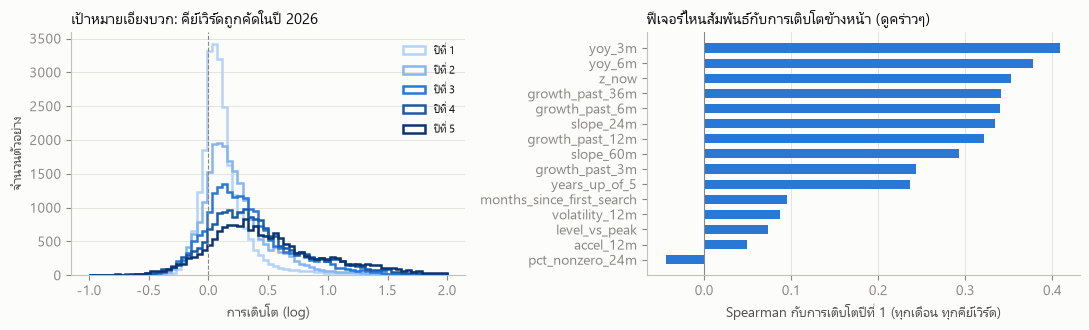

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.1]})

for h in HORIZONS:                                           # การกระจายของเป้าหมายแต่ละปี
    axes[0].hist(samples[f"t_y{h}"].dropna(), bins=70, range=(-1, 2), histtype="step", lw=1.8,
                 color=YEAR_COLORS[h], label=f"ปีที่ {h}")
axes[0].axvline(0, color=GREY, lw=0.8, ls="--")
axes[0].set_xlabel("การเติบโต (log)")
axes[0].set_ylabel("จำนวนตัวอย่าง")
axes[0].set_title("เป้าหมายเอียงบวก: คีย์เวิร์ดถูกคัดในปี 2026")
axes[0].legend()

corr = samples[LONG_FEATURES].corrwith(samples["t_y1"], method="spearman").sort_values()   # ดูคร่าวๆ ไม่ใช่ผลทดสอบ
axes[1].barh(corr.index, corr.values, color=BLUE, height=0.6)
axes[1].axvline(0, color=GREY, lw=0.8)
axes[1].grid(axis="x"); axes[1].grid(axis="y", visible=False)
axes[1].set_xlabel("Spearman กับการเติบโตปีที่ 1 (ทุกเดือน ทุกคีย์เวิร์ด)")
axes[1].set_title("ฟีเจอร์ไหนสัมพันธ์กับการเติบโตข้างหน้า (ดูคร่าวๆ)")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** (ซ้าย) การเติบโตส่วนใหญ่เป็นบวก — คีย์เวิร์ดชุดนี้ถูกคัดในปี 2026 เพราะเป็นกระแส อดีตจึงเอียงไปทางโต (**survivorship bias**)
อัตราโตพื้นฐานสูงกว่าตลาดทั่วไป แต่การเทียบวิธีต่างๆ บนชุดเดียวกันยังเป็นธรรม ·
(ขวา) แต่ละแถวคือตัวอย่างหนึ่งเดือน เดือนติดกันของคำเดียวกันแทบซ้ำกัน จึงไม่ใช่ตัวอย่างอิสระ — กราฟนี้ดูทิศทางเท่านั้น ไม่ใช่ผลทดสอบ

## 3. Modeling

**โมเดล:** RandomForest **ตัวเดียวต่อปี** (ปีที่ 1-5 แยกกัน) เรียนจาก **ทุกคีย์เวิร์ดร่วมกัน** (pooled) แล้วทายการเติบโตของทุกคีย์เวิร์ด ณ เดือนที่สนใจ

- **ทำไมรวมทุกคีย์เวิร์ด:** 1 คีย์เวิร์ดมีประวัติแค่ราว 270 เดือนที่ซ้อนกันมาก เรียนแยกทีละคำไม่พอ แต่รวมกันได้ราว 2 หมื่นตัวอย่าง
  ให้โมเดลเรียน "สภาพแบบนี้ (เก่าแค่ไหน ใกล้จุดสูงสุดไหม โตมาเท่าไร) มักตามด้วยการเติบโตแค่ไหน" ข้ามคำได้
- **ทำไม RandomForest:** รับ NaN ได้, จับความสัมพันธ์ไม่เป็นเส้นตรงได้, ไม่ต้องปรับสเกลฟีเจอร์ · `min_samples_leaf=20` กันเรียนเฉพาะจุด (เสียงรบกวน)
- **สิ่งที่ใช้จริงคือ "ลำดับ"**: backtest ยืนยันได้แค่ว่าเรียงลำดับถูกแค่ไหน ไม่ได้ยืนยันขนาดการโต → คะแนนที่ใช้คือ percentile ของค่าที่ทาย (0.5 = กลางตลาด)

### 3.1 เลือกตัวอย่างฝึกตามเวลา (ข้อสำคัญที่สุดของ backtest)
ตัวอย่างที่เดือน `m` จะมี "เฉลย" ปีที่ h ก็ต่อเมื่อข้อมูลไปถึงเดือน `m + b` แล้ว (b = เดือนสุดท้ายของปีที่ h: 12 / 24 / 36 / 48 / 60)
ดังนั้นถ้าทาย ณ วันที่ `known_until` ต้องฝึกด้วยตัวอย่างที่ **`m + b ≤ known_until`** เท่านั้น — ใช้ตัวอย่างใหม่กว่านี้ = เอาอนาคตมาฝึก (รั่ว)

- ใช้งานจริง: `known_until = LAST_TRUSTED_MONTH` (ตัดช่วงข้อมูลกระโดดออกไปด้วยกลไกเดียวกัน)
- backtest: `known_until = จุดตัดที่กำลังทดสอบ`

In [10]:
def training_set(samples, h, known_until):
    b = HORIZONS[h][1]
    return samples[(samples["month"] + b <= month_index(known_until)) & samples[f"t_y{h}"].notna()]


def fit_model(samples, h, known_until):
    known = training_set(samples, h, known_until)
    assert (known["month"] + HORIZONS[h][1] <= month_index(known_until)).all()      # ไม่รั่ว: เฉลยทุกแถวรู้แล้ว ณ known_until
    if len(known) < 100:
        raise ValueError(f"ตัวอย่างฝึกปีที่ {h} มีแค่ {len(known)} ตัว - ข้อมูลย้อนหลังไม่พอ")
    model = RandomForestRegressor(**RF_PARAMS).fit(known[MODEL_FEATURES[h]], known[f"t_y{h}"])
    return model, len(known)


# ตัวอย่างฝึกที่ใช้ได้ ณ วันที่ต่างๆ: ปีที่ไกลกว่าต้องรอนานกว่าเฉลยจะมา จึงมีตัวอย่างน้อยกว่า
pd.DataFrame({f"ปีที่ {h}": {f"{d:%Y-%m}": len(training_set(samples, h, d))
                              for d in [pd.Timestamp("2016-06-01"), pd.Timestamp("2019-06-01"), pd.Timestamp("2022-06-01"),
                                        LAST_TRUSTED_MONTH]} for h in HORIZONS}).rename_axis("known_until")

,ปีที่ 1,ปีที่ 2,ปีที่ 3,ปีที่ 4,ปีที่ 5
known_until,,,,,
2016-06,8324,6963,5649,4429,3300
2019-06,12572,11093,9678,8324,6963
2022-06,17251,15650,14091,12572,11093
2025-06,22165,20509,18869,17251,15650


### 3.2 เทรนโมเดลที่ใช้งานจริง
ฝึก 5 โมเดล (ปี 1-5) ด้วยข้อมูลทั้งหมดที่เชื่อได้ (`known_until = LAST_TRUSTED_MONTH`) แล้วดูว่าโมเดลใช้ฟีเจอร์ไหนมาก

เทรน 5 โมเดลเสร็จใน 25 วินาที · ตัวอย่างฝึกปี 1-5 = [22165, 20509, 18869, 17251, 15650]


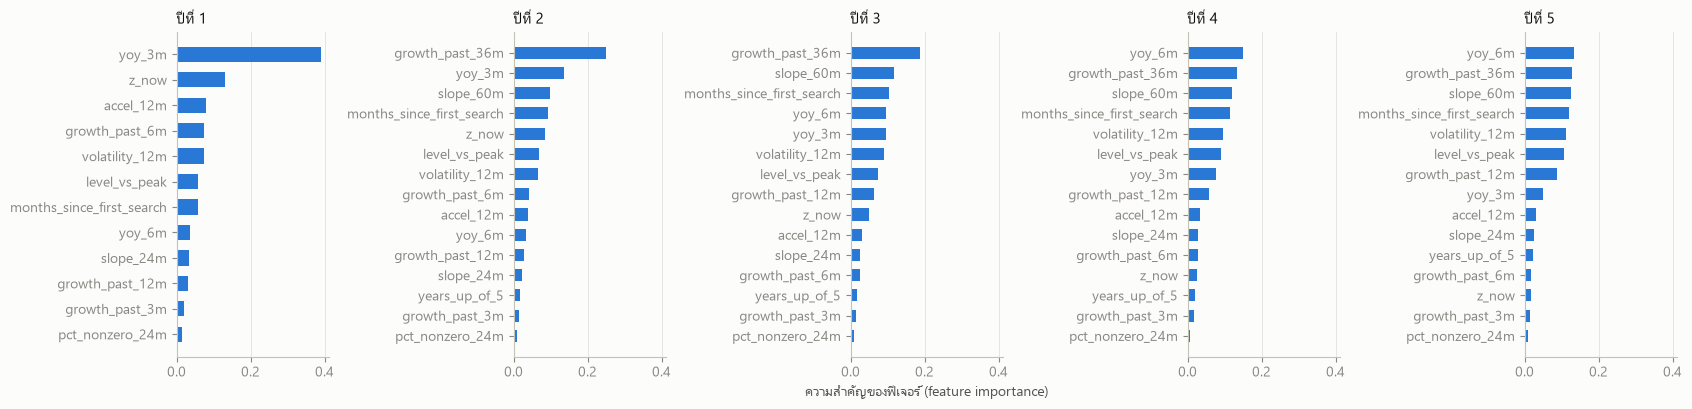

In [11]:
start = time.time()
models, n_train = {}, {}
for h in HORIZONS:
    models[h], n_train[h] = fit_model(samples, h, LAST_TRUSTED_MONTH)
print(f"เทรน {len(HORIZONS)} โมเดลเสร็จใน {time.time() - start:.0f} วินาที · ตัวอย่างฝึกปี 1-5 = {[n_train[h] for h in HORIZONS]}")

fig, axes = plt.subplots(1, len(HORIZONS), figsize=(17, 4.2), sharex=True)
for ax, h in zip(axes, HORIZONS):
    imp = pd.Series(models[h].feature_importances_, index=MODEL_FEATURES[h]).sort_values()
    ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"ปีที่ {h}")
axes[2].set_xlabel("ความสำคัญของฟีเจอร์ (feature importance)")
plt.tight_layout()
plt.show()

### 3.3 ทายเดือนล่าสุด → คะแนน
ใช้ข้อมูลถึงเดือนล่าสุดของแต่ละคีย์เวิร์ด (ที่ข้อมูลพอ) สร้างฟีเจอร์ → ให้ 5 โมเดลทายการเติบโตปี 1-5 แล้วแปลงเป็น **คะแนน = percentile ของค่าที่ทาย** เทียบกับคีย์เวิร์ดทั้งหมดในรอบ

- `BLEND_MOMENTUM = False` (ใช้อยู่ตอนนี้): คะแนน = percentile ของค่าที่โมเดลทายอย่างเดียว
- `BLEND_MOMENTUM = True`: คะแนน = percentile ของ (percentile momentum + percentile ค่าที่ทาย) ÷ 2 — เหตุผลที่ปิดไว้ดูขั้น 5.5
- รายงาน (🆕 2026-10-02) จัดอันดับด้วยปีที่ 2 (ระยะสั้น) และปีที่ 5 (ระยะยาว) และแสดงเป็น % ที่คาด ไม่ใช้คำ "เร็ว/ช้ากว่าตลาด" แล้ว

In [12]:
def predict_latest(series_by_keyword, models):
    rows = []
    for keyword, series in series_by_keyword.items():
        values = series.to_numpy(dtype=float)
        i = len(values) - 1                                  # เดือนล่าสุดของข้อมูล
        if has_enough_data(values, i):                       # thin = ไม่ทาย
            rows.append({"keyword": keyword, **features_at(values, i)})
    kw = pd.DataFrame(rows).set_index("keyword")
    for h, model in models.items():
        kw[f"pred_y{h}"] = model.predict(kw[MODEL_FEATURES[h]])
    kw["momentum"] = kw["growth_past_12m"]
    return kw


def add_scores(kw, use_momentum=BLEND_MOMENTUM):
    kw = kw.copy()
    for h in HORIZONS:
        pred_rank = kw[f"pred_y{h}"].rank(pct=True)
        kw[f"score_y{h}"] = ((kw["momentum"].rank(pct=True) + pred_rank) / 2).rank(pct=True) if use_momentum else pred_rank
    return kw


kw = add_scores(predict_latest(series_by_keyword, models))
view = pd.DataFrame({"คาดปีที่ 2 (%)": np.expm1(kw["pred_y2"]) * 100, "คาดปีที่ 5 (%)": np.expm1(kw["pred_y5"]) * 100,
                     "โต 12 เดือนที่ผ่านมา (%)": np.expm1(kw["momentum"]) * 100,
                     "คะแนนปี 2": kw["score_y2"], "คะแนนปี 5": kw["score_y5"]}).sort_values("คะแนนปี 2", ascending=False).round(2)
print(f"{len(kw)} คีย์เวิร์ด ณ {max(s.index[-1] for s in series_by_keyword.values()):%Y-%m} · 8 อันดับบนและล่างของคะแนนปี 2")
pd.concat([view.head(8), view.tail(8)])

143 คีย์เวิร์ด ณ 2026-08 · 8 อันดับบนและล่างของคะแนนปี 2


,คาดปีที่ 2 (%),คาดปีที่ 5 (%),โต 12 เดือนที่ผ่านมา (%),คะแนนปี 2,คะแนนปี 5
keyword,,,,,
tretinoin,68.84,132.77,37.18,1.00,0.83
skin routine,46.30,164.62,112.82,0.99,0.99
bha exfoliant,45.46,120.44,100.53,0.99,0.71
skin resurfacing,43.83,180.50,61.84,0.98,1.00
aerosol free hairspray,41.01,104.25,210.71,0.97,0.56
tazarotene,40.97,100.77,56.72,0.97,0.50
centella cream,40.20,160.88,103.99,0.96,0.98
hair thickening,39.04,131.14,77.66,0.95,0.81
fragrance free sunscreen,-7.85,42.06,429.31,0.06,0.13


**หมายเหตุ:** "โต 12 เดือนที่ผ่านมา" ของเดือนล่าสุดได้รับผลจากการกระโดดของข้อมูลหลัง ก.ค. 2025 (ขั้น 1.2) จึงสูงเกินจริงทั้งตลาด
ส่วนค่าที่โมเดลทายถูกฝึกจากช่วงที่เชื่อได้เท่านั้น — นี่คือเหตุผลที่คะแนนใช้โมเดลอย่างเดียว (ดูขั้น 5.5)

### 3.4 เช็กว่าโค้ดนี้ให้ค่าตรงกับของจริง
ทำ 3 อย่าง: (ก) ค่าตั้งต้นต้องตรงกับ `growth_score.py` (ข) ตารางตัวอย่างฝึกที่โมดูลสร้างต้องเหมือนตารางข้างบนทุกช่อง
(ค) ค่าที่ทายต้องตรงกับที่บันทึกไว้ใน `phase2_growth_score_result.json` ของรอบนี้ — ไฟล์ที่รายงานใช้จริง

In [13]:
sys.path.insert(0, str(MAIN / "tool" / "phase2_three_streams"))
import growth_score as gs

# (ก) ค่าตั้งต้น
assert (gs.SAMPLE_START, gs.LAST_TRUSTED_MONTH, gs.HORIZONS, gs.MODEL_FEATURES, gs.RF_PARAMS, gs.BLEND_MOMENTUM,
        gs.PIT_SCALING) == (SAMPLE_START, LAST_TRUSTED_MONTH, HORIZONS, MODEL_FEATURES, RF_PARAMS, BLEND_MOMENTUM,
                            PIT_SCALING), "ค่าตั้งต้นไม่ตรงกับ growth_score.py"
print("✅ (ก) ค่าตั้งต้นตรงกับ growth_score.py")

# (ข) ตารางตัวอย่างฝึก
pd.testing.assert_frame_equal(gs.build_samples(series_by_keyword), samples)
print(f"✅ (ข) ตารางตัวอย่างฝึก {samples.shape[0]:,} แถว x {samples.shape[1]} คอลัมน์ ตรงกับ gs.build_samples ทุกช่อง")

# (ค) ค่าที่ทาย เทียบไฟล์ผลของรอบนี้
saved_file = FORECAST_DIR.parent / "phase2_growth_score_result.json"
if saved_file.exists():
    saved = pd.DataFrame(json.loads(saved_file.read_text(encoding="utf-8"))["keywords"]).drop_duplicates("keyword").set_index("keyword")
    worst = max(float((saved.loc[kw.index, f"pred_y{h}"] - kw[f"pred_y{h}"]).abs().max()) for h in HORIZONS)
    worst_score = max(float((saved.loc[kw.index, f"score_y{h}"] - kw[f"score_y{h}"]).abs().max()) for h in HORIZONS)
    print(f"✅ (ค) ค่าที่ทายต่างจากไฟล์ผลจริงมากสุด {worst:.2e} · คะแนนต่างมากสุด {worst_score:.2e}")
    assert worst < 1e-9 and worst_score < 1e-9
else:
    print("⚠️ ไม่พบ", saved_file.name, "- ข้ามข้อ (ค)")

✅ (ก) ค่าตั้งต้นตรงกับ growth_score.py


✅ (ข) ตารางตัวอย่างฝึก 25,803 แถว x 23 คอลัมน์ ตรงกับ gs.build_samples ทุกช่อง
✅ (ค) ค่าที่ทายต่างจากไฟล์ผลจริงมากสุด 4.44e-16 · คะแนนต่างมากสุด 0.00e+00


## 4. Backtest (walk-forward)

**ขั้นตอน** ที่แต่ละจุดตัด `c` (ทุก 6 เดือน 2016-06 ถึง 2022-06 = 13 จุด, ปีที่ 4 ถึง 2021-06 = 11 จุด, ปีที่ 5 ถึง 2020-06 = 9 จุด):
1. ฝึกโมเดลแต่ละปีด้วยตัวอย่างที่ **รู้เฉลยแล้ว ณ วัน `c`** เท่านั้น (`fit_model(known_until=c)` ขั้น 3.1)
2. ทายการเติบโตของทุกคีย์เวิร์ดที่ข้อมูลพอ ณ เดือน `c`
3. เทียบกับ **การเติบโตจริง** ที่เกิดขึ้นหลัง `c` ปีที่ 1-5

```
2008 ──── ฝึก (รู้เฉลยแล้ว ณ c) ──── c ── ปี 1 ── ปี 2 ── ปี 3 ── ปี 4 ── ปี 5 ── 2025-06 (LAST_TRUSTED)
                                       ↑ ทาย ณ จุดนี้ └───── เฉลยจริง (โมเดลไม่เห็น) ─────┘
```

จุดตัดสุดท้ายของปีที่ h = จุดที่ +12h เดือนยังไม่เกิน 2025-06 (ก่อนข้อมูลกระโดด) · โมเดลถูกเทรนใหม่ทุกจุดตัด (13+13+13+11+9 = 59 โมเดล)

ข้างเคียงกับโมเดล เก็บคำตอบของวิธีเทียบไว้ในตารางเดียวกัน (ไม่ต้องฝึก):
- **momentum** — ปีที่แล้วโตเท่าไร ทายว่าปีหน้าโตมากตามนั้น (`growth_past_12m`)
- **mean reversion** — ทายว่าจะกลับเข้าระดับปกติ: ตอนนี้สูงกว่าปกติ (z สูง) จะโตน้อย → คะแนน = `−z_now` เป็นตัวแทนของ Z_Delta เดิม (ที่ ⑦ ทายการกลับเข้าระดับปกติ)
- **blend** — เฉลี่ย percentile ของ momentum กับโมเดล (`BLEND_MOMENTUM = True`)

In [14]:
def walk_forward(samples, eval_cutoffs):
    rows = []
    for cutoff in eval_cutoffs:
        now = samples[samples["month"] == month_index(cutoff)]               # คีย์เวิร์ดที่ต้องเรียงลำดับ ณ จุดตัดนี้
        for h in HORIZONS:
            if cutoff not in cutoffs_for(h):                                 # เฉลยปีที่ h ยังไม่ครบก่อน 2025-06
                continue
            model, n = fit_model(samples, h, known_until=cutoff)             # ฝึกด้วยเฉลยที่รู้แล้ว ณ วัน cutoff เท่านั้น
            test = now[now[f"t_y{h}"].notna()]
            rows.append(pd.DataFrame({
                "horizon": h, "cutoff": cutoff, "keyword": test["keyword"].to_numpy(),
                "model": model.predict(test[MODEL_FEATURES[h]]),             # โมเดลทายการเติบโต
                "momentum": test["growth_past_12m"].to_numpy(),              # วิธีเทียบ 1
                "mean_reversion": -test["z_now"].to_numpy(),                 # วิธีเทียบ 2
                "actual": test[f"t_y{h}"].to_numpy(),                        # เฉลยจริง
                "n_train": n}))
    return pd.concat(rows, ignore_index=True)


start = time.time()
bt = walk_forward(samples, EVAL_CUTOFFS)
rank = lambda col: bt.groupby(["horizon", "cutoff"])[col].rank(pct=True)
bt["blend"] = (rank("model") + rank("momentum")) / 2                         # วิธีเทียบ 3: เฉลี่ย percentile ภายในจุดตัดเดียวกัน
print(f"เสร็จใน {(time.time() - start) / 60:.1f} นาที · {len(bt):,} คำตอบ = {bt['keyword'].nunique()} คีย์เวิร์ด x {bt['cutoff'].nunique()} จุดตัด x {len(HORIZONS)} ปี")

(bt.groupby(["cutoff", "horizon"]).agg(n_keywords=("keyword", "size"), n_train=("n_train", "first"))
   .unstack("horizon").rename(columns={"n_keywords": "คีย์เวิร์ดที่ทาย", "n_train": "ตัวอย่างฝึก"}).rename_axis("จุดตัด"))

เสร็จใน 2.3 นาที · 7,463 คำตอบ = 136 คีย์เวิร์ด x 13 จุดตัด x 5 ปี


คีย์เวิร์ดที่ทาย                             ตัวอย่างฝึก                                   
horizon                   1      2      3      4      5           1        2        3        4       5
จุดตัด                                                                                                
2016-06-01            115.0  115.0  115.0  115.0  115.0      8324.0   6963.0   5649.0   4429.0  3300.0
2016-12-01            118.0  118.0  118.0  118.0  118.0      9000.0   7646.0   6297.0   5026.0  3858.0
2017-06-01            120.0  120.0  120.0  120.0  120.0      9678.0   8324.0   6963.0   5649.0  4429.0
2017-12-01            123.0  123.0  123.0  123.0  123.0     10375.0   9000.0   7646.0   6297.0  5026.0
2018-06-01            124.0  124.0  124.0  124.0  124.0     11093.0   9678.0   8324.0   6963.0  5649.0
2018-12-01            127.0  127.0  127.0  127.0  127.0     11829.0  10375.0   9000.0   7646.0  6297.0
2019-06-01            129.0  129.0  129.0  129.0  129.0     12572.0  11093.0   9678.0   8324.0  6963.0
2019-12-01            129.0  129.0  129.0  129.0  129.0     13325.0  11829.0  10375.0   9000.0  7646.0
2020-06-01            132.0  132.0  132.0  132.0  132.0     14091.0  12572.0  11093.0   9678.0  8324.0
2020-12-01            133.0  133.0  133.0  133.0    NaN     14863.0  13325.0  11829.0  10375.0     NaN
2021-06-01            134.0  134.0  134.0  134.0    NaN     15650.0  14091.0  12572.0  11093.0     NaN
2021-12-01            134.0  134.0  134.0    NaN    NaN     16448.0  14863.0  13325.0      NaN     NaN
2022-06-01            136.0  136.0  136.0    NaN    NaN     17251.0  15650.0  14091.0      NaN     NaN

ตัวอย่างฝึกเพิ่มขึ้นตามเวลา (จุดตัดหลังๆ ได้เรียนจากอดีตมากขึ้น เหมือนใช้งานจริง) และจำนวนคีย์เวิร์ดที่ทายได้เพิ่มตามที่คำใหม่ๆ มีข้อมูลพอ

## 5. Evaluation

### 5.1 วิธีวัด
ธุรกิจต้องการ **"เรียงลำดับว่าเทรนด์ไหนโตมากกว่า"** เพื่อคัด Top N ไม่ใช่ทายเลข % ให้แม่น จึงวัดที่ลำดับ

| ตัวชี้วัด | ความหมาย |
|---|---|
| **Spearman** (หลัก) | ที่แต่ละจุดตัด เทียบ "ลำดับที่ทาย" กับ "ลำดับการโตจริง" (1 = เรียงถูกหมด, 0 = สุ่ม, ติดลบ = เรียงกลับทาง) แล้วเฉลี่ยทุกจุดตัด (ปีที่ 4 = 11, ปีที่ 5 = 9) |
| **Top 20% โตจริง** | ใน 20% ที่ทายว่าโตมากที่สุด กี่ % ที่โตจริงเกิน 10% เทียบอัตราพื้นฐาน (ถ้าสุ่มเลือกจะได้เท่าอัตราพื้นฐาน) |
| **ชนะ momentum** | ใน 13 จุดตัด วิธีนี้ Spearman สูงกว่า momentum กี่จุด + ผลต่างเฉลี่ยกับช่วงความเชื่อมั่น 95% (bootstrap ข้ามจุดตัด) |

ไม่ใช้ "ทายถูกว่าจะโตหรือไม่" เพราะคีย์เวิร์ดชุดนี้โตเกือบทุกปี การทายว่าโตทุกครั้งก็ถูกเกือบหมดแล้ว

### 5.2 ผลระดับคีย์เวิร์ด

In [15]:
METHODS = {"model": "โมเดล (ใช้อยู่ตอนนี้)", "momentum": "momentum", "blend": "blend (momentum + โมเดล)",
           "mean_reversion": "mean reversion (ตัวแทน Z_Delta เดิม)"}


def spearman_per_cutoff(df, column):
    return df.groupby("cutoff").apply(lambda g: spearmanr(g[column], g["actual"]).statistic)


def top20(df, column):
    hit, avg_growth = [], []
    for _, g in df.groupby("cutoff"):
        top = g.nlargest(max(1, int(len(g) * 0.2)), column)
        hit.append((top["actual"] > GROWTH_THRESHOLD).mean())
        avg_growth.append(np.expm1(top["actual"].mean()) * 100)
    return 100 * np.mean(hit), np.mean(avg_growth)


def bootstrap_ci(values, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    means = [rng.choice(values, len(values)).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])


per_cutoff = {(h, m): spearman_per_cutoff(bt[bt["horizon"] == h], m) for h in HORIZONS for m in METHODS}

spearman_table = pd.DataFrame({f"ปีที่ {h}": {METHODS[m]: per_cutoff[(h, m)].mean() for m in METHODS} for h in HORIZONS})
print("Spearman เฉลี่ยทุกจุดตัด (สูง = เรียงลำดับตรงกับการโตจริง; ปีที่ 4 = 11, ปีที่ 5 = 9 จุดตัด)")
display(spearman_table.round(3))
print("ช่วงของ Spearman ต่อจุดตัด (ต่ำสุด ถึง สูงสุด) - ดูว่ามีจุดตัดไหนเรียงผิดทางไหม")
display(pd.DataFrame({f"ปีที่ {h}": {METHODS[m]: f"{per_cutoff[(h, m)].min():+.2f} ถึง {per_cutoff[(h, m)].max():+.2f}"
                                      for m in METHODS} for h in HORIZONS}))

hit_rows = {METHODS[m]: {f"ปีที่ {h}": top20(bt[bt["horizon"] == h], m)[0] for h in HORIZONS} for m in METHODS}
hit_rows["อัตราพื้นฐาน (สุ่มเลือก)"] = {f"ปีที่ {h}": 100 * (bt.loc[bt["horizon"] == h, "actual"] > GROWTH_THRESHOLD).mean()
                                          for h in HORIZONS}
print("Top 20% ที่ทายว่าโตมากสุด โตจริงเกิน 10% กี่ %")
display(pd.DataFrame(hit_rows).T.round(1))

Spearman เฉลี่ยทุกจุดตัด (สูง = เรียงลำดับตรงกับการโตจริง; ปีที่ 4 = 11, ปีที่ 5 = 9 จุดตัด)


,ปีที่ 1,ปีที่ 2,ปีที่ 3,ปีที่ 4,ปีที่ 5
โมเดล (ใช้อยู่ตอนนี้),0.527,0.475,0.461,0.458,0.409
momentum,0.436,0.448,0.454,0.451,0.453
blend (momentum + โมเดล),0.530,0.508,0.505,0.506,0.498
mean reversion (ตัวแทน Z_Delta เดิม),-0.335,-0.283,-0.270,-0.242,-0.213


ช่วงของ Spearman ต่อจุดตัด (ต่ำสุด ถึง สูงสุด) - ดูว่ามีจุดตัดไหนเรียงผิดทางไหม


,ปีที่ 1,ปีที่ 2,ปีที่ 3,ปีที่ 4,ปีที่ 5
โมเดล (ใช้อยู่ตอนนี้),+0.33 ถึง +0.67,+0.25 ถึง +0.60,+0.25 ถึง +0.55,+0.23 ถึง +0.63,+0.26 ถึง +0.54
momentum,+0.19 ถึง +0.60,+0.16 ถึง +0.60,+0.21 ถึง +0.57,+0.28 ถึง +0.58,+0.25 ถึง +0.56
blend (momentum + โมเดล),+0.30 ถึง +0.68,+0.23 ถึง +0.65,+0.27 ถึง +0.62,+0.32 ถึง +0.65,+0.30 ถึง +0.63
mean reversion (ตัวแทน Z_Delta เดิม),-0.52 ถึง -0.15,-0.49 ถึง -0.10,-0.47 ถึง -0.05,-0.46 ถึง -0.04,-0.45 ถึง -0.04


Top 20% ที่ทายว่าโตมากสุด โตจริงเกิน 10% กี่ %


,ปีที่ 1,ปีที่ 2,ปีที่ 3,ปีที่ 4,ปีที่ 5
โมเดล (ใช้อยู่ตอนนี้),79.8,87.5,90.9,95.1,94.5
momentum,72.8,84.5,90.7,94.2,95.9
blend (momentum + โมเดล),81.4,88.2,93.2,97.0,96.4
mean reversion (ตัวแทน Z_Delta เดิม),28.5,49.8,56.6,62.6,66.5
อัตราพื้นฐาน (สุ่มเลือก),49.2,67.7,74.1,78.3,81.5


In [16]:
pairs = [("model", "momentum"), ("blend", "momentum"), ("blend", "model")]
rows = []
for h in HORIZONS:
    for a, b in pairs:
        diff = per_cutoff[(h, a)] - per_cutoff[(h, b)]
        low, high = bootstrap_ci(diff)
        rows.append({"ปี": h, "เทียบ": f"{a} − {b}", "ผลต่าง Spearman เฉลี่ย": diff.mean(), "CI 95% ต่ำ": low, "CI 95% สูง": high,
                     "ชนะกี่จุดตัด": f"{int((diff > 0).sum())}/{len(diff)}"})
print("ผลต่างแบบจับคู่ต่อจุดตัด (CI = bootstrap ข้ามจุดตัด; จุดตัดห่างกัน 6 เดือน แต่ช่วงผลจริงซ้อนกัน จึงแคบกว่าความจริง)")
pd.DataFrame(rows).set_index(["ปี", "เทียบ"]).round(3)

ผลต่างแบบจับคู่ต่อจุดตัด (CI = bootstrap ข้ามจุดตัด; จุดตัดห่างกัน 6 เดือน แต่ช่วงผลจริงซ้อนกัน จึงแคบกว่าความจริง)


ผลต่าง Spearman เฉลี่ย  CI 95% ต่ำ  CI 95% สูง ชนะกี่จุดตัด
ปี เทียบ                                                                        
1  model − momentum                   0.091       0.024       0.155         9/13
   blend − momentum                   0.094       0.060       0.128        12/13
   blend − model                      0.004      -0.030       0.037         7/13
2  model − momentum                   0.027      -0.018       0.074         9/13
   blend − momentum                   0.060       0.038       0.081        11/13
   blend − model                      0.033       0.004       0.059        10/13
3  model − momentum                   0.007      -0.029       0.051         4/13
   blend − momentum                   0.050       0.034       0.069        13/13
   blend − model                      0.043       0.018       0.065        11/13
4  model − momentum                   0.007      -0.037       0.054         6/11
   blend − momentum                   0.055       0.035       0.078        10/11
   blend − model                      0.048       0.022       0.074        10/11
5  model − momentum                  -0.044      -0.083      -0.009          2/9
   blend − momentum                   0.045       0.028       0.057          8/9
   blend − model                      0.089       0.063       0.115          9/9

### 5.3 แยกตามจุดตัด
ความสามารถเรียงลำดับคงที่หรือขึ้นลงตามช่วงเวลา (เส้นประเทา = mean reversion ซึ่งเป็นตัวแทน Z_Delta เดิม)

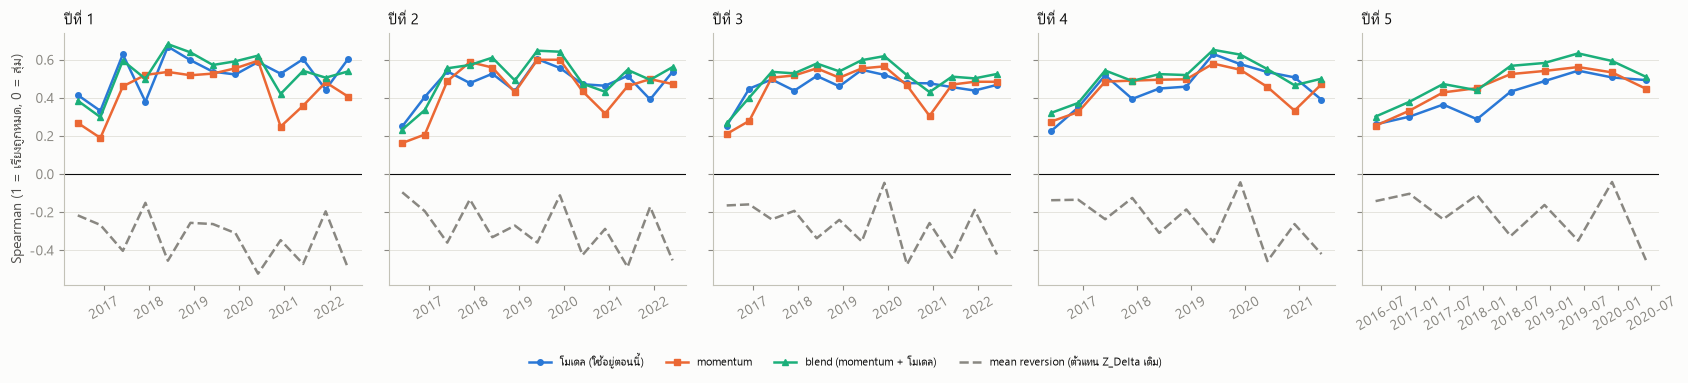

In [17]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(17, 3.8), sharey=True)
styles = {"model": (BLUE, "-", "o"), "momentum": (ORANGE, "-", "s"), "blend": (AQUA, "-", "^"), "mean_reversion": (GREY, "--", None)}
for ax, h in zip(axes, HORIZONS):
    for m, (color, ls, marker) in styles.items():
        s = per_cutoff[(h, m)]
        ax.plot(s.index, s.values, color=color, ls=ls, marker=marker, ms=4, label=METHODS[m])
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"ปีที่ {h}")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Spearman (1 = เรียงถูกหมด, 0 = สุ่ม)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

### 5.4 ระดับเทรนด์ (หน่วยที่ขึ้นรายงานจริง)
รายงานจัดอันดับ **เทรนด์** (กลุ่มคีย์เวิร์ด) ไม่ใช่คีย์เวิร์ด โหมดปัจจุบันให้คะแนนเทรนด์จาก "การเติบโตที่คาดของดัชนีเทรนด์"
(ตัวเลข "คาด +X%" ในรายงาน) ที่ทำแบบนี้:

- ดัชนีเทรนด์ = ค่าเฉลี่ยของคีย์เวิร์ดในเทรนด์ (ที่ข้อมูลพอ) — ตัวเดียวกับกราฟหน้าเทรนด์
- ระดับที่คาด = เฉลี่ยของ `(ค่าเฉลี่ย 12 เดือนล่าสุดของคำ + 1) × exp(ค่าที่ทาย) − 1` ข้ามคำในเทรนด์ แล้วเทียบกับระดับฐาน
- เทียบกับการเติบโตจริงของดัชนีเทรนด์ — เรียงลำดับ 15 เทรนด์ ที่แต่ละจุดตัด

ได้ข้อมูลเพียง 15 เทรนด์ x 13 จุดตัด (ปีที่ 5 มี 9) และเทรนด์ใช้คีย์เวิร์ดที่ถูกคัดมาแล้ว ตัวเลขนี้จึงสั่นไหวกว่าระดับคีย์เวิร์ด

ตารางที่สองคือ **ความแม่นของขนาด** (ตัวเลข "คาด +X%"): ผลจริง ÷ ที่ทาย ของระดับดัชนีเทรนด์ — ค่ากลางความคลาดเคลื่อน และช่วงที่ครอบ
ผลจริง 80% (เปอร์เซ็นไทล์ 10-90) · `growth_score.FORECAST_BAND_80` ใช้ค่าเดียวกันนี้แต่คำนวณจากข้อมูล 2 รอบรวมกัน (082438 + 111455)

In [18]:
def past_means(keyword, cutoff):
    s = series_by_keyword[keyword]
    i, v = s.index.get_loc(cutoff), s.to_numpy(dtype=float)
    return v[i - 11:i + 1].mean(), v[i - 23:i - 11].mean()


bt_trend = bt.copy()
levels_at = [past_means(k, c) for k, c in zip(bt_trend["keyword"], bt_trend["cutoff"])]
bt_trend["past12"], bt_trend["prev12"] = [a for a, _ in levels_at], [b for _, b in levels_at]
bt_trend = bt_trend.merge(mapping, left_on="keyword", right_on="Keyword")      # คำที่อยู่ 2 เทรนด์นับทั้งสองเทรนด์


def trend_growth(g):
    base = g["past12"].mean()
    return pd.Series({
        "model": log_growth(((g["past12"] + 1) * np.exp(g["model"]) - 1).mean(), base),         # การเติบโตที่คาดของดัชนีเทรนด์
        "momentum": log_growth(base, g["prev12"].mean()),                                          # การโตของดัชนีเทรนด์ปีที่ผ่านมา
        "actual": log_growth(((g["past12"] + 1) * np.exp(g["actual"]) - 1).mean(), base)})       # การโตจริงของดัชนีเทรนด์


trend_bt = bt_trend.groupby(["horizon", "cutoff", "cluster_name"]).apply(trend_growth).reset_index()
trend_spearman = {(h, m): trend_bt[trend_bt["horizon"] == h].groupby("cutoff").apply(
    lambda g: spearmanr(g[m], g["actual"]).statistic) for h in HORIZONS for m in ("model", "momentum")}

print(f"{trend_bt['cluster_name'].nunique()} เทรนด์ x {trend_bt['cutoff'].nunique()} จุดตัด")
display(pd.DataFrame({f"ปีที่ {h}": {"โมเดล (การเติบโตที่คาดของดัชนีเทรนด์)": trend_spearman[(h, "model")].mean(),
                                      "momentum ของดัชนีเทรนด์": trend_spearman[(h, "momentum")].mean()}
                      for h in HORIZONS}).round(3))

ratio = np.expm1(trend_bt["actual"] - trend_bt["model"])                      # ผลจริง ÷ ที่ทาย - 1 (ระดับดัชนีเทรนด์)
size = pd.DataFrame({f"ปีที่ {h}": {
    "ค่ากลางความคลาดเคลื่อน (%)": 100 * ratio[trend_bt["horizon"] == h].abs().median(),
    "ทายว่าไม่เปลี่ยน (%)": 100 * np.expm1(trend_bt.loc[trend_bt["horizon"] == h, "actual"]).abs().median(),
    "ช่วง 80%: ต่ำ (%)": 100 * ratio[trend_bt["horizon"] == h].quantile(0.10),
    "ช่วง 80%: สูง (%)": 100 * ratio[trend_bt["horizon"] == h].quantile(0.90),
    "ผลจริงสูงกว่าที่ทาย (% ของกรณี)": 100 * (ratio[trend_bt["horizon"] == h] > 0).mean()} for h in HORIZONS})
print("ความแม่นของขนาด (ระดับดัชนีเทรนด์ รอบ 082438)")
size.round(1)

15 เทรนด์ x 13 จุดตัด


,ปีที่ 1,ปีที่ 2,ปีที่ 3,ปีที่ 4,ปีที่ 5
โมเดล (การเติบโตที่คาดของดัชนีเทรนด์),0.432,0.388,0.328,0.344,0.287
momentum ของดัชนีเทรนด์,0.360,0.354,0.378,0.318,0.337


ความแม่นของขนาด (ระดับดัชนีเทรนด์ รอบ 082438)


,ปีที่ 1,ปีที่ 2,ปีที่ 3,ปีที่ 4,ปีที่ 5
ค่ากลางความคลาดเคลื่อน (%),6.0,8.2,12.1,16.6,19.9
ทายว่าไม่เปลี่ยน (%),10.1,20.7,32.8,45.8,60.0
ช่วง 80%: ต่ำ (%),-9.8,-13.0,-15.7,-21.5,-13.6
ช่วง 80%: สูง (%),13.8,18.9,25.2,40.6,56.8
ผลจริงสูงกว่าที่ทาย (% ของกรณี),57.9,54.4,64.6,67.3,77.8


### 5.5 ทำไมตอนนี้ใช้โมเดลอย่างเดียว (`BLEND_MOMENTUM = False`)
ในอดีต momentum กับโมเดลเห็นตรงกันเป็นส่วนใหญ่ (คำที่โตมาก่อนมักถูกทายว่าโตต่อ) แต่ใน **ข้อมูลล่าสุด** การกระโดดของ cat=0 ทำให้ momentum
(12 เดือนล่าสุด ÷ 12 เดือนก่อน) สูงเกินจริงและไม่สัมพันธ์กับสิ่งที่โมเดลทาย — เทียบความสอดคล้อง (Spearman ระหว่างค่าที่โมเดลทายกับ momentum) ในอดีตกับตอนนี้

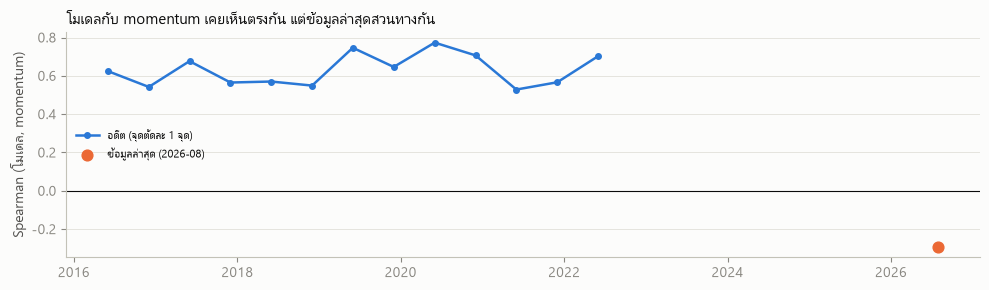

อดีต: เฉลี่ย +0.63 (ต่ำสุด +0.53) · ล่าสุด: -0.29


In [19]:
agree_history = bt[bt["horizon"] == 1].groupby("cutoff").apply(lambda g: spearmanr(g["model"], g["momentum"]).statistic)
agree_now = spearmanr(kw["pred_y1"], kw["momentum"]).statistic

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(agree_history.index, agree_history.values, color=BLUE, marker="o", ms=4, label="อดีต (จุดตัดละ 1 จุด)")
ax.scatter([max(s.index[-1] for s in series_by_keyword.values())], [agree_now], color=ORANGE, s=60, zorder=3, label="ข้อมูลล่าสุด (2026-08)")
ax.axhline(0, color=INK, lw=0.8)
ax.set_ylabel("Spearman (โมเดล, momentum)")
ax.set_title("โมเดลกับ momentum เคยเห็นตรงกัน แต่ข้อมูลล่าสุดสวนทางกัน")
ax.legend(loc="center left")
plt.tight_layout()
plt.show()
print(f"อดีต: เฉลี่ย {agree_history.mean():+.2f} (ต่ำสุด {agree_history.min():+.2f}) · ล่าสุด: {agree_now:+.2f}")

คะแนนแบบผสมจึงพาเทรนด์ไปคนละทางกับ "คาด +X%" ในรายงาน (เช่นเกรด "ช้ากว่าตลาด" ติดกับ "คาด +9%") — เลือกใช้โมเดลอย่างเดียวจนกว่าข้อมูลจะพ้นช่วงกระโดด
(`MOMENTUM_CLEAN_FROM = 2027-07` โค้ดเตือนให้เองตอนข้อมูลถึง)

### 5.6 สรุปผล
**ที่มาของตัวเลข:** รันเมื่อ 2 ต.ค. 2026 · ข้อมูลรอบ 082438 (143 คีย์เวิร์ดที่ข้อมูลพอ, 15 เทรนด์) · 13 จุดตัด 2016-06 ถึง 2022-06
(ปีที่ 4 = 11, ปีที่ 5 = 9 จุดตัด) · ราว 127 คีย์เวิร์ดต่อจุดตัด · ตั้ง `random_state` ตายตัว รันซ้ำควรได้เท่าเดิม ·
ยืนยันซ้ำกับรอบ 111455 (คีย์เวิร์ดซ้ำกันแค่ 16 คำ) ด้วยสคริปต์แยก

**Spearman เฉลี่ย (ระดับคีย์เวิร์ด, ยิ่งสูงยิ่งเรียงลำดับตรงกับการโตจริง):**

| วิธี | ปีที่ 1 | ปีที่ 2 | ปีที่ 3 | ปีที่ 4 | ปีที่ 5 |
|---|---|---|---|---|---|
| โมเดล (ใช้อยู่ตอนนี้) | +0.527 | +0.475 | +0.461 | +0.458 | +0.409 |
| momentum | +0.436 | +0.448 | +0.454 | +0.451 | +0.453 |
| blend (momentum + โมเดล) | **+0.530** | **+0.508** | **+0.505** | **+0.506** | **+0.498** |
| mean reversion (ตัวแทน Z_Delta เดิม) | −0.335 | −0.283 | −0.270 | −0.242 | −0.213 |

1. **ฟีเจอร์ใหม่ 3 ตัว (2 ต.ค. 2026) ช่วยจริง:** โมเดลเดิม 0.485 / 0.438 / 0.434 (ปี 1-3) และปีที่ 5 ราว 0.36 → ตอนนี้ 0.527 / 0.475 / 0.461 / 0.409
   รอบ 111455 ไปทางเดียวกัน (0.472 → 0.507 ปี 1, 0.432 → 0.473 ปี 2, 0.378 → 0.396 ปี 5)
2. **mean reversion เรียงกลับทางทุกปีและทุกจุดตัด** — ยืนยันว่า Z_Delta เดิมไม่ใช่ตัวจัดอันดับการโต
3. **โมเดลเทียบ momentum:** ปีที่ 1 ดีกว่าชัด (+0.091, CI ไม่คร่อม 0, ชนะ 9/13) ปีที่ 2-4 ใกล้กัน และ**ปีที่ 5 แย่กว่า** (−0.044, ชนะ 2/9)
   ส่วน **blend ดีที่สุดทุกปี** (ชนะ momentum +0.045 ถึง +0.094 และชนะโมเดลปีที่ 2-5) แต่ตอนนี้ปิดไว้เพราะข้อมูลกระโดด (ขั้น 5.5)
   → ระยะยาว (ปีที่ 5) ได้ประโยชน์จากการเปิด blend มากที่สุด เมื่อมีข้อมูลที่ไม่กระโดด (cat=143)
4. **Top 20% ที่ทายว่าโตมากสุด** โตจริงเกิน 10%: ปีที่ 2 = 87.5% เทียบอัตราพื้นฐาน 67.7% · ปีที่ 5 = 94.5% เทียบ 81.5%
5. **ระดับเทรนด์ (15 เทรนด์):** 0.43 / 0.39 / 0.33 / 0.34 / 0.29 (รอบ 111455: 0.45 / 0.43 / 0.37 / 0.39 / 0.41) — สั่นไหวมากเพราะมีแค่ 15 เทรนด์
6. **ขนาด ("คาด +X%"):** ค่ากลางความคลาดเคลื่อน 6 / 8 / 12 / 17 / 20% (ทายว่าไม่เปลี่ยน 10 / 21 / 33 / 46 / 60%) · ปีไกลโมเดลมักทาย
   **ต่ำกว่าจริง** (ผลจริงสูงกว่า 58% ของกรณีในปีที่ 1, 78% ในปีที่ 5) เพราะคีย์เวิร์ดชุดนี้ถูกเลือกตอนที่ดังแล้ว ·
   `growth_score.FORECAST_BAND_80` คิดจากข้อมูล 2 รอบรวมกัน: −10..+12% / −15..+19% / −21..+26% / −25..+35% / −27..+48%
7. **`PIT_SCALING` (ปรับสเกลตัวอย่างฝึก ณ เดือนนั้น) ทดสอบแล้วแต่ยังปิด:** backtest จัดอันดับดีกว่า (2 รอบข้อมูล: ปีที่ 2 0.50, ปีที่ 5 0.45)
   แต่กับข้อมูลจริงตอนนี้อันดับเปลี่ยนมาก (Safe Inhalation Spray จากที่ 7 ขึ้นที่ 1 — เทรนด์ที่ข้อมูลกระโดดหนักสุด) และ % ที่คาดสูงขึ้นอีก
   (ค่ากลางตลาดปีที่ 5 +133% เทียบ +101%) พิสูจน์ไม่ได้ว่าเป็นของจริง — เจ้าของงานเลือกเปิดหลังดึงข้อมูล cat=143

**ข้อจำกัด (อ่านก่อนเอาตัวเลขไปอ้าง):**
- **Survivorship bias:** คีย์เวิร์ดถูกคัดในปี 2026 เพราะเป็นกระแส อดีตเอียงไปทางโต (โตเกิน 10%: 49% ในปีที่ 1 ถึง 82% ในปีที่ 5)
  ตัวเลขแม่นสัมบูรณ์อาจเกินจริง แต่การเทียบวิธีต่างๆ บนชุดเดียวกันยังเป็นธรรม · ตรวจจับ "เทรนด์ที่กำลังเสื่อม" ไม่ได้เพราะไม่มีคำที่ล้มเหลวในชุดนี้
- **ปีที่ 4-5 ทดสอบได้น้อยกว่า:** จุดตัดสุดท้าย 2021-06 / 2020-06 และฝึกจากอดีตที่สั้นกว่า (จุดตัดแรกของปีที่ 5 มีตัวอย่างฝึกแค่ราว 3,300)
- **ช่วงความเชื่อมั่นแคบกว่าความจริง:** จุดตัดห่างกัน 6 เดือน แต่ช่วงผลจริง 1-5 ปีซ้อนกัน และเป็นคีย์เวิร์ดชุดเดียวกันทุกจุดตัด
- **ยังไม่ได้ทดสอบกับข้อมูลหลังการกระโดดของ cat=0:** ฟีเจอร์การโตของเดือนล่าสุด (รวม `yoy_3m` / `yoy_6m` ที่เพิ่มใหม่) สูงทั้งตลาดเพราะการกระโดด
  ซึ่งอยู่นอกช่วงที่โมเดลเคยเห็นในอดีต — ทางแก้ที่แท้จริงคือดึงข้อมูลแบบระบุหมวด (cat=143) แล้วขยับ `LAST_TRUSTED_MONTH`
